# 🐢 La tortuga hambrienta: solución explicada paso a paso
**Actividad de iniciación · Programación (0485) · 1.º DAW**

Vamos a programar un **prototipo de juego** con el módulo `turtle`, que viene incluido con Python: una tortuga se mueve con las flechas del teclado y tiene que comerse **5 lechugas** que aparecen en sitios al azar.

En cada fase verás: 🎯 **qué** hay que conseguir, 🧠 **cómo** pensarlo, 💻 **el código** explicado y 🔬 **una prueba** que puedes ejecutar.

> ⚠️ **Importante.** `turtle` abre una **ventana**, y Google Colab no tiene pantalla. Por eso aquí usamos una **tortuga simulada**: el código del juego es *el mismo* que en `tortuga.py`, pero los dibujos aparecen como imágenes dentro del cuaderno y las teclas las "pulsamos" con `pantalla.pulsar("Up")`. Al final puedes descargar `tortuga.py` para jugar en tu ordenador.

Ejecuta las celdas **en orden** (`Mayús + Intro`) o usa *Entorno de ejecución → Ejecutar todas*.

## 0. Preparación: una tortuga "de mentira"
La siguiente celda crea un objeto `turtle` que se usa igual que el de verdad (`turtle.Screen()`, `turtle.Turtle()`, `forward`, `left`, `goto`, `write`…) pero que dibuja en memoria. No hace falta entenderla por dentro: basta con ejecutarla.

In [1]:
# --- Simulador de turtle para Colab (no forma parte del juego) ---
import io, math, random
from types import SimpleNamespace
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont, ImageColor
from IPython.display import display, Image as IPyImage

_FORMAS = {
    "turtle": ((0,16), (-2,14), (-1,10), (-4,7), (-7,9), (-9,8), (-6,5), (-7,1), (-5,-3), (-8,-6),
               (-6,-8), (-4,-5), (0,-7), (4,-5), (6,-8), (8,-6), (5,-3), (7,1), (6,5), (9,8),
               (7,9), (4,7), (1,10), (2,14)),
    "circle": tuple((10 * math.sin(math.radians(a)), 10 * math.cos(math.radians(a))) for a in range(0, 360, 18)),
    "classic": ((0,0), (-5,-9), (0,-7), (5,-9)),
}
_FUENTE = font_manager.findfont("DejaVu Sans:bold")


class _Pantalla:
    def __init__(self):
        self.ancho, self.alto, self.fondo = 600, 600, "white"
        self.tortugas, self.teclas = [], {}

    def setup(self, ancho, alto): self.ancho, self.alto = ancho, alto
    def title(self, texto): pass
    def bgcolor(self, color): self.fondo = color
    def onkey(self, funcion, tecla): self.teclas[tecla] = funcion
    def listen(self): pass
    def tracer(self, *a): pass
    def update(self): pass

    def pulsar(self, tecla):
        """Solo en el simulador: equivale a pulsar una tecla."""
        if tecla in self.teclas:
            self.teclas[tecla]()

    def _px(self, x, y):
        return (self.ancho / 2 + x, self.alto / 2 - y)

    def imagen(self):
        img = Image.new("RGB", (self.ancho, self.alto), ImageColor.getrgb(self.fondo))
        d = ImageDraw.Draw(img)
        for t in self.tortugas:
            for (a, b, color, grosor) in t._trazos:
                d.line([self._px(*a), self._px(*b)], fill=color, width=max(1, int(grosor)))
            for (pos, texto, align, tam, color) in t._textos:
                anc = {"left": "ls", "center": "ms", "right": "rs"}[align]
                d.text(self._px(*pos), texto, fill=color, font=ImageFont.truetype(_FUENTE, int(tam * 1.25)), anchor=anc)
        for t in self.tortugas:
            if t._visible:
                h = math.radians(t._rumbo - 90)
                pts = [self._px(t._x + px * math.cos(h) - py * math.sin(h), t._y + px * math.sin(h) + py * math.cos(h))
                       for (px, py) in _FORMAS[t._forma]]
                d.polygon(pts, fill=t._color, outline="black")
        return img


class Turtle:
    def __init__(self):
        self._x = self._y = 0.0
        self._rumbo, self._lapiz, self._color, self._grosor = 0.0, True, "black", 1
        self._visible, self._forma = True, "classic"
        self._trazos, self._textos = [], []
        pantalla_actual.tortugas.append(self)

    # Aspecto
    def shape(self, nombre): self._forma = nombre
    def color(self, c): self._color = c
    def pensize(self, g): self._grosor = g
    def speed(self, v): pass
    def hideturtle(self): self._visible = False
    def showturtle(self): self._visible = True
    def penup(self): self._lapiz = False
    def pendown(self): self._lapiz = True

    # Movimiento
    def goto(self, x, y):
        if self._lapiz:
            self._trazos.append(((self._x, self._y), (x, y), self._color, self._grosor))
        self._x, self._y = float(x), float(y)
    def forward(self, d):
        r = math.radians(self._rumbo)
        self.goto(round(self._x + d * math.cos(r), 6), round(self._y + d * math.sin(r), 6))
    def backward(self, d): self.forward(-d)
    def left(self, a): self._rumbo = (self._rumbo + a) % 360
    def right(self, a): self._rumbo = (self._rumbo - a) % 360
    def setheading(self, a): self._rumbo = a % 360
    def heading(self): return self._rumbo
    def xcor(self): return self._x
    def ycor(self): return self._y
    def position(self): return (self._x, self._y)
    def distance(self, otra):
        return math.hypot(self._x - otra._x, self._y - otra._y)

    # Texto
    def write(self, texto, align="left", font=("Arial", 8, "normal")):
        self._textos.append(((self._x, self._y), str(texto), align, font[1], self._color))
    def clear(self):
        self._trazos, self._textos = [], []


def _Screen():
    return pantalla_actual

pantalla_actual = _Pantalla()
turtle = SimpleNamespace(Screen=_Screen, Turtle=Turtle, done=lambda: None)


def mostrar(*imagenes, titulos=None, ancho=4.5):
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho))
    if len(imagenes) == 1:
        ejes = [ejes]
    for i, (eje, img) in enumerate(zip(ejes, imagenes)):
        eje.imshow(img); eje.axis("off")
        if titulos: eje.set_title(titulos[i])
    plt.tight_layout(); plt.show()

print("Tortuga simulada lista ✔")

Tortuga simulada lista ✔


---
## Fase 1 · Pintar el campo

🎯 **Objetivo:** abrir la ventana con fondo verde y dibujar el **borde del campo**: un cuadrado de lado 500 centrado en el origen.

### 🧠 Cómo pensarlo
- En `turtle`, el punto `(0, 0)` está en el **centro** de la ventana; la `y` crece **hacia arriba** (al revés que en Pygame Zero).
- Si el campo va de `-LIMITE` a `LIMITE`, su esquina inferior izquierda es `(-LIMITE, -LIMITE)` y cada lado mide `LIMITE * 2`.
- Para no pintar el camino hasta la esquina, levantamos el lápiz (`penup()`), vamos allí (`goto`) y lo bajamos (`pendown()`).
- Un cuadrado son **4 veces** "avanza y gira 90°": un bucle `for`.

Usamos una tortuga **invisible** (`lapiz`) solo para dibujar.

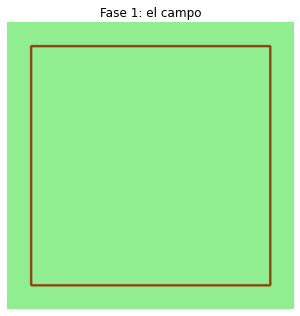

In [2]:
LIMITE = 250              # el campo va de -250 a 250 en x y en y
PASO = 20                 # píxeles que avanza la tortuga en cada pulsación
LECHUGAS_PARA_GANAR = 5

pantalla = turtle.Screen()
pantalla.setup(600, 600)
pantalla.title("La tortuga hambrienta - 1º DAW")
pantalla.bgcolor("lightgreen")

lapiz = turtle.Turtle()
lapiz.hideturtle()
lapiz.speed(0)


def dibujar_campo():
    """Fase 1: dibuja el borde del campo con un bucle."""
    lapiz.penup()
    lapiz.goto(-LIMITE, -LIMITE)
    lapiz.pendown()
    lapiz.pensize(5)
    lapiz.color("saddlebrown")
    for lado in range(4):
        lapiz.forward(LIMITE * 2)
        lapiz.left(90)


dibujar_campo()
mostrar(pantalla.imagen(), titulos=["Fase 1: el campo"])

> 💡 **Prueba tú:** cambia `range(4)` por `range(3)` y `left(90)` por `left(120)`. ¿Qué figura sale? (Recuerda volver a dejarlo como estaba).

---
## Fase 2 · La tortuga y la lechuga

🎯 **Objetivo:** crear la tortuga protagonista y una lechuga colocada en un **sitio al azar** dentro del campo.

### 🧠 Cómo pensarlo
- Cada personaje es un objeto `turtle.Turtle()`. Con `shape("turtle")` y `shape("circle")` cambiamos su forma.
- `penup()` es imprescindible: si no, ¡la tortuga dejaría un rastro por todo el campo!
- `random.randint(a, b)` da un entero al azar entre `a` y `b`. Restamos 20 al límite para que la lechuga no quede pegada al borde.
- Colocar la lechuga lo haremos **muchas veces** (al empezar y cada vez que se la coma), así que lo metemos en una función.

La lechuga está en (-109.0, 73.0)
La lechuga está en (48.0, -164.0)
La lechuga está en (-41.0, 79.0)
La lechuga está en (12.0, 90.0)


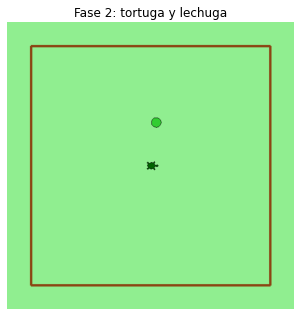

In [3]:
tortuga = turtle.Turtle()
tortuga.shape("turtle")
tortuga.color("darkgreen")
tortuga.speed(0)
tortuga.penup()

lechuga = turtle.Turtle()
lechuga.shape("circle")
lechuga.color("limegreen")
lechuga.speed(0)
lechuga.penup()


def colocar_lechuga():
    """Fase 2: pone la lechuga en un sitio al azar dentro del campo."""
    x = random.randint(-LIMITE + 20, LIMITE - 20)
    y = random.randint(-LIMITE + 20, LIMITE - 20)
    lechuga.goto(x, y)


random.seed(3)
for intento in range(4):
    colocar_lechuga()
    print("La lechuga está en", lechuga.position())
mostrar(pantalla.imagen(), titulos=["Fase 2: tortuga y lechuga"])

---
## Fase 3 · Mover la tortuga con las flechas

🎯 **Objetivo:** que cada flecha mueva la tortuga `PASO` píxeles en esa dirección.

### 🧠 Cómo pensarlo
- `setheading(angulo)` orienta la tortuga: **0 = derecha, 90 = arriba, 180 = izquierda, 270 = abajo**. Después, `forward(PASO)` la hace avanzar.
- Las cuatro flechas hacen lo mismo con un ángulo distinto, así que escribimos **una** función con un **parámetro**, `avanzar(direccion)`, y cuatro funciones cortas que la llaman.
- `pantalla.onkey(funcion, "Up")` significa: *"cuando se pulse la flecha arriba, ejecuta `funcion`"*. Ojo: se pasa el **nombre** de la función, **sin paréntesis**.
- `pantalla.listen()` hace que la ventana "escuche" el teclado.

In [4]:
def avanzar(direccion):                  # versión FASE 3
    tortuga.setheading(direccion)
    tortuga.forward(PASO)


def arriba():
    avanzar(90)


def abajo():
    avanzar(270)


def izquierda():
    avanzar(180)


def derecha():
    avanzar(0)


pantalla.onkey(arriba, "Up")
pantalla.onkey(abajo, "Down")
pantalla.onkey(izquierda, "Left")
pantalla.onkey(derecha, "Right")
pantalla.listen()
print("Teclas asociadas:", list(pantalla.teclas))

Teclas asociadas: ['Up', 'Down', 'Left', 'Right']


### 🔬 Prueba: pulsamos una secuencia de flechas
Bajamos el lápiz de la tortuga solo para ver el camino que recorre.

Posición final: (-60.0, -40.0) · mirando hacia 270 grados


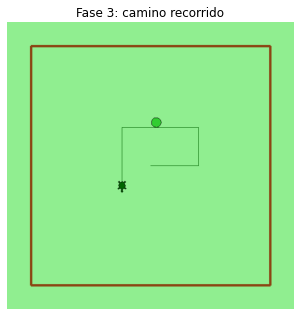

In [5]:
tortuga.goto(0, 0)
tortuga.pendown()
secuencia = ["Right"] * 5 + ["Up"] * 4 + ["Left"] * 8 + ["Down"] * 6
for tecla in secuencia:
    pantalla.pulsar(tecla)
print("Posición final:", tortuga.position(), "· mirando hacia", tortuga.heading(), "grados")
mostrar(pantalla.imagen(), titulos=["Fase 3: camino recorrido"])
tortuga.clear()          # borramos el rastro
tortuga.penup()

---
## Fase 4 · No salir del campo

🎯 **Objetivo:** la tortuga no puede atravesar el borde.

### 🧠 Cómo pensarlo
- `tortuga.xcor()` y `tortuga.ycor()` dan su posición. Está fuera si `x` o `y` se pasan del límite **por cualquiera de los dos lados**. `abs()` (valor absoluto) nos ahorra comprobar el lado positivo y el negativo por separado.
- Dejamos un margen de 10 píxeles para que la tortuga no pise la línea.
- La forma más sencilla de impedir el movimiento: **avanzar y, si se ha salido, retroceder** (`backward(PASO)`).

Tras pulsar → 30 veces: x = 240.0
Tras pulsar ↓ 30 veces: y = -240.0


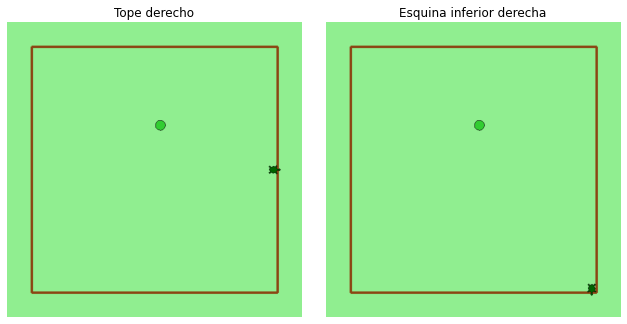

In [6]:
def avanzar(direccion):                  # versión FASE 4
    tortuga.setheading(direccion)
    tortuga.forward(PASO)
    if abs(tortuga.xcor()) > LIMITE - 10 or abs(tortuga.ycor()) > LIMITE - 10:
        tortuga.backward(PASO)      # se saldría: deshacemos el paso


tortuga.goto(0, 0)
for _ in range(30):
    pantalla.pulsar("Right")
print("Tras pulsar → 30 veces: x =", tortuga.xcor())
captura_derecha = pantalla.imagen()

for _ in range(30):
    pantalla.pulsar("Down")
print("Tras pulsar ↓ 30 veces: y =", tortuga.ycor())
mostrar(captura_derecha, pantalla.imagen(), titulos=["Tope derecho", "Esquina inferior derecha"])

✔ Por mucho que pulsemos, la tortuga se queda en `240` (que es `LIMITE - 10`): el `if` deshace el paso que la sacaría del campo.

---
## Fase 5 · ¡A comer! Marcador y victoria

🎯 **Objetivo:** cuando la tortuga llega a la lechuga, suma un punto y la lechuga aparece en otro sitio. Con 5 lechugas, ¡has ganado!

### 🧠 Cómo pensarlo
- `tortuga.distance(lechuga)` nos dice a cuántos píxeles están. Si es menor que `PASO`, se la ha comido.
- `puntos` es una variable **global** que la función modifica: necesita `global puntos`.
- Para escribir en pantalla usamos otra tortuga invisible, `marcador`. Antes de escribir, `clear()` borra el texto anterior (si no, los números se amontonarían).
- Cuando `puntos == LECHUGAS_PARA_GANAR`, escondemos la lechuga, mostramos el mensaje final y `avanzar()` ya no mueve la tortuga.

x =  20.0 · distancia a la lechuga =   40.0 · puntos = 0
x =  40.0 · distancia a la lechuga =   20.0 · puntos = 0
x =  60.0 · distancia a la lechuga =  197.1 · puntos = 1


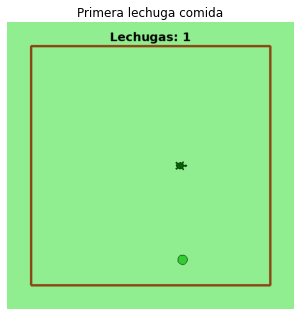

In [7]:
marcador = turtle.Turtle()
marcador.hideturtle()
marcador.penup()

puntos = 0


def escribir_marcador(texto):
    marcador.clear()
    marcador.goto(0, LIMITE + 10)
    marcador.write(texto, align="center", font=("Arial", 20, "bold"))


def comprobar_lechuga():
    """Fase 5: si la tortuga llega a la lechuga, suma un punto."""
    global puntos
    if tortuga.distance(lechuga) < PASO:
        puntos += 1
        if puntos == LECHUGAS_PARA_GANAR:
            lechuga.hideturtle()
            escribir_marcador("¡Has ganado! Te has comido " + str(puntos) + " lechugas")
        else:
            colocar_lechuga()
            escribir_marcador("Lechugas: " + str(puntos))


def avanzar(direccion):                  # versión FINAL
    """Fases 3 y 4: gira hacia 'direccion', avanza y no sale del campo."""
    if puntos == LECHUGAS_PARA_GANAR:
        return                      # la partida ha terminado
    tortuga.setheading(direccion)
    tortuga.forward(PASO)
    if abs(tortuga.xcor()) > LIMITE - 10 or abs(tortuga.ycor()) > LIMITE - 10:
        tortuga.backward(PASO)      # se saldría: deshacemos el paso
    comprobar_lechuga()


escribir_marcador("Lechugas: 0")
tortuga.goto(0, 0)
lechuga.goto(60, 0)                 # lechuga a 3 pasos a la derecha
for _ in range(3):
    pantalla.pulsar("Right")
    print(f"x = {tortuga.xcor():>5} · distancia a la lechuga = {tortuga.distance(lechuga):6.1f} · puntos = {puntos}")
mostrar(pantalla.imagen(), titulos=["Primera lechuga comida"])

---
## 🎬 Partida completa simulada
Un "robot" pulsa las flechas para acercarse a la lechuga (primero en horizontal y luego en vertical). Guardamos una imagen tras cada pulsación y las unimos en un GIF.

Lechugas: 5 · pulsaciones: 99 · fotogramas: 115


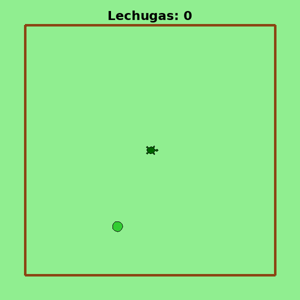

In [8]:
def robot():
    """Elige la flecha que acerca la tortuga a la lechuga."""
    dx = lechuga.xcor() - tortuga.xcor()
    dy = lechuga.ycor() - tortuga.ycor()
    if abs(dx) > PASO / 2:
        return "Right" if dx > 0 else "Left"
    return "Up" if dy > 0 else "Down"


random.seed(7)
puntos = 0
tortuga.goto(0, 0)
lechuga.showturtle()
colocar_lechuga()
escribir_marcador("Lechugas: 0")

fotogramas = [pantalla.imagen().resize((300, 300))]
pulsaciones = 0
while puntos < LECHUGAS_PARA_GANAR and pulsaciones < 500:
    pantalla.pulsar(robot())
    pulsaciones += 1
    fotogramas.append(pantalla.imagen().resize((300, 300)))
fotogramas += [fotogramas[-1]] * 15

buffer = io.BytesIO()
fotogramas[0].save(buffer, format="GIF", save_all=True, append_images=fotogramas[1:],
                   duration=120, loop=0, optimize=True)
print(f"Lechugas: {puntos} · pulsaciones: {pulsaciones} · fotogramas: {len(fotogramas)}")
display(IPyImage(data=buffer.getvalue(), format="gif"))

Tras ganar, pulsar ↑ ya no mueve la tortuga: (-180.0, -40.0)


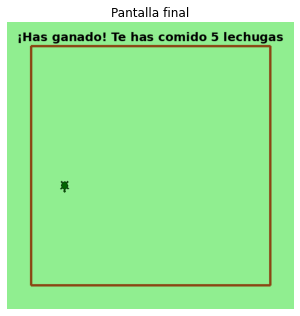

In [9]:
pantalla.pulsar("Up")
print("Tras ganar, pulsar ↑ ya no mueve la tortuga:", tortuga.position())
mostrar(pantalla.imagen(), titulos=["Pantalla final"])

---
## 📦 El programa completo: `tortuga.py`
Esta celda guarda la solución completa (con `import turtle` de verdad y `turtle.done()` al final). Para jugar en tu ordenador **no hay que instalar nada**: `turtle` viene con Python.
```
python tortuga.py
```
> 💡 Haz clic en la ventana antes de pulsar las flechas, para que tenga el foco del teclado.

In [10]:
%%writefile tortuga.py
# Solución de referencia - Actividad "La tortuga hambrienta" (1º DAW - Programación)
import random
import turtle

# Constantes
LIMITE = 250              # el campo va de -250 a 250 en x y en y
PASO = 20                 # píxeles que avanza la tortuga en cada pulsación
LECHUGAS_PARA_GANAR = 5

# Ventana
pantalla = turtle.Screen()
pantalla.setup(600, 600)
pantalla.title("La tortuga hambrienta - 1º DAW")
pantalla.bgcolor("lightgreen")

# Tortugas auxiliares: una para dibujar y otra para escribir
lapiz = turtle.Turtle()
lapiz.hideturtle()
lapiz.speed(0)

marcador = turtle.Turtle()
marcador.hideturtle()
marcador.penup()

# Personajes
tortuga = turtle.Turtle()
tortuga.shape("turtle")
tortuga.color("darkgreen")
tortuga.speed(0)
tortuga.penup()

lechuga = turtle.Turtle()
lechuga.shape("circle")
lechuga.color("limegreen")
lechuga.speed(0)
lechuga.penup()

puntos = 0


def dibujar_campo():
    """Fase 1: dibuja el borde del campo con un bucle."""
    lapiz.penup()
    lapiz.goto(-LIMITE, -LIMITE)
    lapiz.pendown()
    lapiz.pensize(5)
    lapiz.color("saddlebrown")
    for lado in range(4):
        lapiz.forward(LIMITE * 2)
        lapiz.left(90)


def colocar_lechuga():
    """Fase 2: pone la lechuga en un sitio al azar dentro del campo."""
    x = random.randint(-LIMITE + 20, LIMITE - 20)
    y = random.randint(-LIMITE + 20, LIMITE - 20)
    lechuga.goto(x, y)


def escribir_marcador(texto):
    marcador.clear()
    marcador.goto(0, LIMITE + 10)
    marcador.write(texto, align="center", font=("Arial", 20, "bold"))


def comprobar_lechuga():
    """Fase 5: si la tortuga llega a la lechuga, suma un punto."""
    global puntos
    if tortuga.distance(lechuga) < PASO:
        puntos += 1
        if puntos == LECHUGAS_PARA_GANAR:
            lechuga.hideturtle()
            escribir_marcador("¡Has ganado! Te has comido " + str(puntos) + " lechugas")
        else:
            colocar_lechuga()
            escribir_marcador("Lechugas: " + str(puntos))


def avanzar(direccion):
    """Fases 3 y 4: gira hacia 'direccion', avanza y no sale del campo."""
    if puntos == LECHUGAS_PARA_GANAR:
        return                      # la partida ha terminado
    tortuga.setheading(direccion)
    tortuga.forward(PASO)
    if abs(tortuga.xcor()) > LIMITE - 10 or abs(tortuga.ycor()) > LIMITE - 10:
        tortuga.backward(PASO)      # se saldría: deshacemos el paso
    comprobar_lechuga()


def arriba():
    avanzar(90)


def abajo():
    avanzar(270)


def izquierda():
    avanzar(180)


def derecha():
    avanzar(0)


# Programa principal
dibujar_campo()
colocar_lechuga()
escribir_marcador("Lechugas: 0")

pantalla.onkey(arriba, "Up")
pantalla.onkey(abajo, "Down")
pantalla.onkey(izquierda, "Left")
pantalla.onkey(derecha, "Right")
pantalla.listen()

turtle.done()

Overwriting tortuga.py


In [11]:
# Descarga tortuga.py a tu ordenador (solo funciona dentro de Google Colab)
try:
    from google.colab import files
    files.download("tortuga.py")
except ImportError:
    print("No estás en Colab: el fichero tortuga.py está en la carpeta actual.")

No estás en Colab: el fichero tortuga.py está en la carpeta actual.


---
## 🧾 Resumen

| Fase | Qué hace | Conceptos |
|---|---|---|
| 1 | Pintar el campo | `turtle.Screen()`, `penup/goto/pendown`, bucle `for` |
| 2 | Tortuga y lechuga | objetos `Turtle`, `shape()`, `random.randint()`, funciones |
| 3 | Mover con flechas | `setheading()`, `forward()`, función con parámetro, `onkey()` |
| 4 | No salir del campo | `if`, `or`, `abs()`, `xcor()/ycor()` |
| 5 | Comer y ganar | `distance()`, `global`, `write()`, `clear()` |

## 🐞 Errores frecuentes

| Síntoma | Causa probable | Solución |
|---|---|---|
| Las flechas no hacen nada | Falta `pantalla.listen()` o la ventana no tiene el foco | Añade `listen()` y haz clic en la ventana |
| La tortuga se mueve una vez al arrancar y luego no | `onkey(arriba(), "Up")` con paréntesis | Pasa el nombre: `onkey(arriba, "Up")` |
| La tortuga deja un rastro | Falta `tortuga.penup()` | Llámalo al crearla |
| Los números del marcador se amontonan | Falta `marcador.clear()` | Bórralo antes de escribir |
| `UnboundLocalError: puntos` | Falta `global puntos` | Añádelo al principio de la función |
| La ventana se cierra sola | Falta `turtle.done()` | Ponlo en la última línea |

## ✅ Autoevaluación

<details><summary><b>1. ¿Qué cambia si pones <code>PASO = 40</code>?</b></summary>
La tortuga avanza el doble en cada pulsación y también es más fácil "comerse" la lechuga, porque la comprobación es <code>distance &lt; PASO</code>.
</details>

<details><summary><b>2. ¿Por qué hay cuatro funciones (<code>arriba</code>, <code>abajo</code>…) si todas llaman a <code>avanzar</code>?</b></summary>
Porque <code>onkey()</code> necesita una función <b>sin parámetros</b>. Cada una "fija" el ángulo y llama a <code>avanzar(angulo)</code>.
</details>

<details><summary><b>3. ¿Qué pasaría sin <code>abs()</code> en la Fase 4?</b></summary>
Solo controlaríamos los bordes derecho y superior (valores positivos); la tortuga podría salir por la izquierda y por abajo.
</details>

<details><summary><b>4. ¿Cómo harías que se ganara con 10 lechugas?</b></summary>
Cambiando una sola línea: <code>LECHUGAS_PARA_GANAR = 10</code>.
</details>

➡️ **Siguiente paso:** *Atrapa la estrella*, con Pygame Zero.